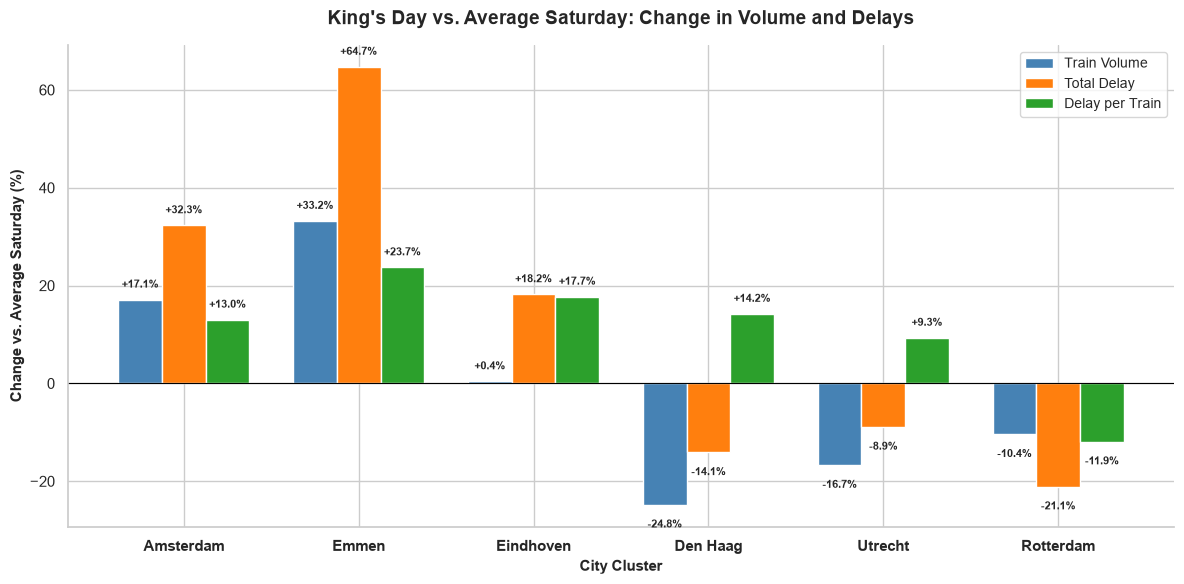

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

#Data definitions
file_path = r"C:\Users\chris\OneDrive - Delft University of Technology\Year 2026-2027\TIL6022 Groep 14\traindata_filtered_2024.csv"
KINGS_DAY = "2024-04-27"

target_stations = [
    "Amsterdam Bijlmer ArenA",
    "Amsterdam Centraal",
    "Amsterdam Holendrecht",
    "Amsterdam Lelylaan",
    "Amsterdam Muiderpoort",
    "Amsterdam RAI",
    "Amsterdam Science Park",
    "Amsterdam Sloterdijk",
    "Amsterdam Zuid",
    "Rotterdam Alexander",
    "Rotterdam Blaak",
    "Rotterdam Centraal",
    "Rotterdam Lombardijen",
    "Rotterdam Noord",
    "Rotterdam Zuid",
    "Den Haag Centraal",
    "Den Haag HS",
    "Den Haag Laan v NOI",
    "Den Haag Mariahoeve",
    "Den Haag Moerwijk",
    "Den Haag Ypenburg",
    "Utrecht Centraal",
    "Eindhoven Centraal",
    "Emmen",
    "Emmen Zuid",
]

# 1. Load and Filter
cols = ["Service:Date", "Service:RDT-ID", "Stop:Station name", "Stop:Arrival delay"]
df = pd.read_csv(file_path, usecols=cols)
df["Service:Date"] = pd.to_datetime(df["Service:Date"])
df = df[df["Stop:Station name"].isin(target_stations)].copy()
df["Stop:Arrival delay"] = pd.to_numeric(
    df["Stop:Arrival delay"], errors="coerce"
).fillna(0.0)


# 2. Map to Cities
def get_parent_city(station_name):
  if station_name.startswith("Amsterdam"):
    return "Amsterdam"
  if station_name.startswith("Rotterdam"):
    return "Rotterdam"
  if station_name.startswith("Den Haag"):
    return "Den Haag"
  if "Utrecht" in station_name:
    return "Utrecht"
  if "Eindhoven" in station_name:
    return "Eindhoven"
  if "Emmen" in station_name:
    return "Emmen"
  return "Other"


df["City"] = df["Stop:Station name"].apply(get_parent_city)
df = df[df["City"] != "Other"]

df["Date_Str"] = df["Service:Date"].dt.strftime("%Y-%m-%d")
df["DayOfWeek"] = df["Service:Date"].dt.dayofweek

# 3. Aggregate daily totals per city
daily = (
    df.groupby(["City", "Date_Str", "DayOfWeek"])
    .agg(
        Trains=("Service:RDT-ID", "nunique"),
        Total_Delay=("Stop:Arrival delay", "sum"),
    )
    .reset_index()
)

# 4. Separate Baseline Saturdays vs King's Day
sat_baseline = daily[(daily["DayOfWeek"] == 5) & (daily["Date_Str"] != KINGS_DAY)]
kings_day = daily[daily["Date_Str"] == KINGS_DAY].set_index("City")

sat_avg = sat_baseline.groupby("City")[["Trains", "Total_Delay"]].mean()
sat_avg["Delay_Per_Train"] = sat_avg["Total_Delay"] / sat_avg["Trains"]
kings_day["Delay_Per_Train"] = kings_day["Total_Delay"] / kings_day["Trains"]

# 5. Calculate percentage changes for all 3 metrics
res = pd.DataFrame(index=sat_avg.index)
res["Train Volume Change (%)"] = (
    (kings_day["Trains"] / sat_avg["Trains"] - 1) * 100
)
res["Total Delay Change (%)"] = (
    (kings_day["Total_Delay"] / sat_avg["Total_Delay"] - 1) * 100
)
res["Delay Per Train Change (%)"] = (
    (kings_day["Delay_Per_Train"] / sat_avg["Delay_Per_Train"] - 1) * 100
)

res = res.round(1)
city_order = ["Amsterdam", "Emmen", "Eindhoven", "Den Haag", "Utrecht", "Rotterdam"]
res = res.reindex([c for c in city_order if c in res.index])

# 6. Plotting all 3 metrics in a Grouped Bar Chart
sns.set_theme(style="whitegrid")
metrics = [
    "Train Volume Change (%)",
    "Total Delay Change (%)",
    "Delay Per Train Change (%)",
]
labels = ["Train Volume", "Total Delay", "Delay per Train"]
colors = ["#4682B4", "#FF7F0E", "#2ca02c"]

x = np.arange(len(res.index))
w = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
for i, (m, lab, col) in enumerate(zip(metrics, labels, colors)):
  bars = ax.bar(x + (i - 1) * w, res[m], width=w, label=lab, color=col)
  for b in bars:
    h = b.get_height()
    ax.text(
        b.get_x() + b.get_width() / 2,
        h + (2 if h >= 0 else -3),
        f"{h:+.1f}%",
        ha="center",
        va="bottom" if h >= 0 else "top",
        fontsize=8,
        fontweight="bold",
    )

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(res.index, fontweight="bold")
ax.set_xlabel("City Cluster", fontweight="bold", fontsize=11)
ax.set_ylabel("Change vs. Average Saturday (%)", fontweight="bold", fontsize=11)
ax.set_title(
    "King's Day vs. Average Saturday: Change in Volume and Delays",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.legend(fontsize=10)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()